# 03 — Моделювання: K-Means і Gaussian Mixture
TUKE OZ · CRISP-DM: Modeling → Evaluation

**Дослідницьке питання:** чи утворюють 29 масштабованих ознак групи, які можна відтворювано описати?
Це перше порівняння двох методів, а не завершений пошук найкращої моделі.
Цільових міток немає; `sample_submission.csv` не є ground truth.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src/modeling.py').is_file(), 'Запусти з кореня проєкту або notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
REPORT = ROOT / 'reports/modeling'
# True: повністю повторити навчання; False: показати вже збережений запуск.
RECOMPUTE = False
if RECOMPUTE or not (REPORT / 'summary.json').exists():
    from modeling import main
    main(ROOT)
summary = json.loads((REPORT / 'summary.json').read_text())
assert hashlib.sha256((ROOT / 'data/data.csv').read_bytes()).hexdigest() == summary['source_sha256'], 'Дані змінились: повтори етапи 02 та 03.'
search = pd.read_csv(REPORT / 'search_metrics.csv')
final = pd.read_csv(REPORT / 'final_metrics.csv')
stability = pd.read_csv(REPORT / 'seed_stability.csv')

## 1. Як працюють методи

**K-Means:** знаходить k центрів і мінімізує суму квадратів відстаней точок до найближчого центру (inertia). Найприродніше описує компактні групи; масштаби ознак впливають на результат.

**Gaussian Mixture (GMM):** описує дані сумішшю k гаусівських компонент. `covariance_type='full'` дозволяє кожній компоненті мати власну форму та орієнтацію. Дає ймовірності належності; їхній максимум — впевненість самої моделі, а не доведена правильність відповіді.

Номери кластерів довільні: кластер 0 одного методу не обов’язково відповідає кластеру 0 іншого.

## 2. Протокол експерименту

- 29 ознак після StandardScaler; ID виключений, порядок рядків збережено.
- Пошук k = 2…10 на одній випадковій вибірці 20 000 рядків, seed=42.
- Для Silhouette — ті самі 2 000 рядків цієї вибірки для всіх кандидатів.
- K-Means: 5 ініціалізацій; GMM: 1, full covariance, max_iter=200, reg_covar=1e-6.
- Вибираємо K-Means за найбільшим Silhouette, GMM — за найменшим BIC. Неконверговані кандидати виключаємо з вибору.
- Для вибраних k перевіряємо seeds 42, 43, 44 на тій самій вибірці.
- Фінальний fit на 98 000 рядків: K-Means 10 ініціалізацій, GMM 2. Для обох однакова нова підвибірка 2 000 рядків для Silhouette.

Це **трансдуктивний аналіз** всього набору, не незалежний train/test експеримент. Масштабування з етапу 02 використовує всі рядки. Для оцінки роботи на нових даних необхідний окремий протокол без такого використання відкладених даних.

## 3. Що означають метрики

| Метрика | Що показує |
|---|---|
| Silhouette | Наскільки точка близька до своєї групи порівняно із сусідньою; вище краще, близько 0 — слабке відокремлення за цією відстанню. |
| Calinski–Harabasz | Співвідношення розкиду між групами та всередині них; вище краще. |
| Davies–Bouldin | Подібність груп з урахуванням їхнього розкиду; нижче краще. |
| Inertia | Сума квадратів відстаней до центрів K-Means. Зі зростанням k зазвичай зменшується, тому сам мінімум не визначає k. |
| BIC / AIC | Баланс відповідності GMM даним і складності; нижче краще в межах порівнюваного набору моделей на тих самих даних. |
| ARI між запусками | Узгодженість двох поділів незалежно від нумерації кластерів; 1 — однаковий поділ. Тут це стабільність, а не accuracy. |

Геометричні метрики можуть віддавати перевагу компактним групам K-Means. Їх не слід використовувати як єдиний доказ переваги над GMM.

,family,k,fit_rows,seed,fit_seconds,converged,iterations,warnings,silhouette_sample,calinski_harabasz,davies_bouldin,observed_clusters,smallest_cluster,largest_cluster,inertia,bic,aic
0,KMeans,2,20000,42,0.301954,True,24,NaN,0.043403,841.145571,4.690217,2,7656,12344,558282.255083,NaN,NaN
1,KMeans,3,20000,42,0.058737,True,17,NaN,0.039311,727.933384,4.535124,3,3810,8284,542283.893247,NaN,NaN
2,KMeans,4,20000,42,0.073088,True,34,NaN,0.036503,643.365636,4.277703,4,3408,6316,530553.777174,NaN,NaN
3,KMeans,5,20000,42,0.085339,True,37,NaN,0.036015,579.304623,4.133763,5,3056,4467,521345.622271,NaN,NaN
4,KMeans,6,20000,42,0.101670,True,29,NaN,0.033093,519.489541,4.077752,6,2646,3950,514876.164760,NaN,NaN
5,KMeans,7,20000,42,0.169183,True,83,NaN,0.031626,472.835680,3.993605,7,2576,3374,509470.349207,NaN,NaN
6,KMeans,8,20000,42,0.187631,True,166,NaN,0.032413,437.128276,3.961044,8,2253,2866,504541.121751,NaN,NaN
7,KMeans,9,20000,42,0.154537,True,61,NaN,0.031096,404.655016,3.960546,9,2008,2476,500685.798390,NaN,NaN
8,KMeans,10,20000,42,0.227595,True,113,NaN,0.030237,376.459326,3.884111,10,1724,2413,497450.809547,NaN,NaN
9,GaussianMixture,2,20000,42,0.050179,True,7,NaN,0.037853,733.627225,5.051020,2,7906,12094,NaN,1.620969e+06,1.613626e+06


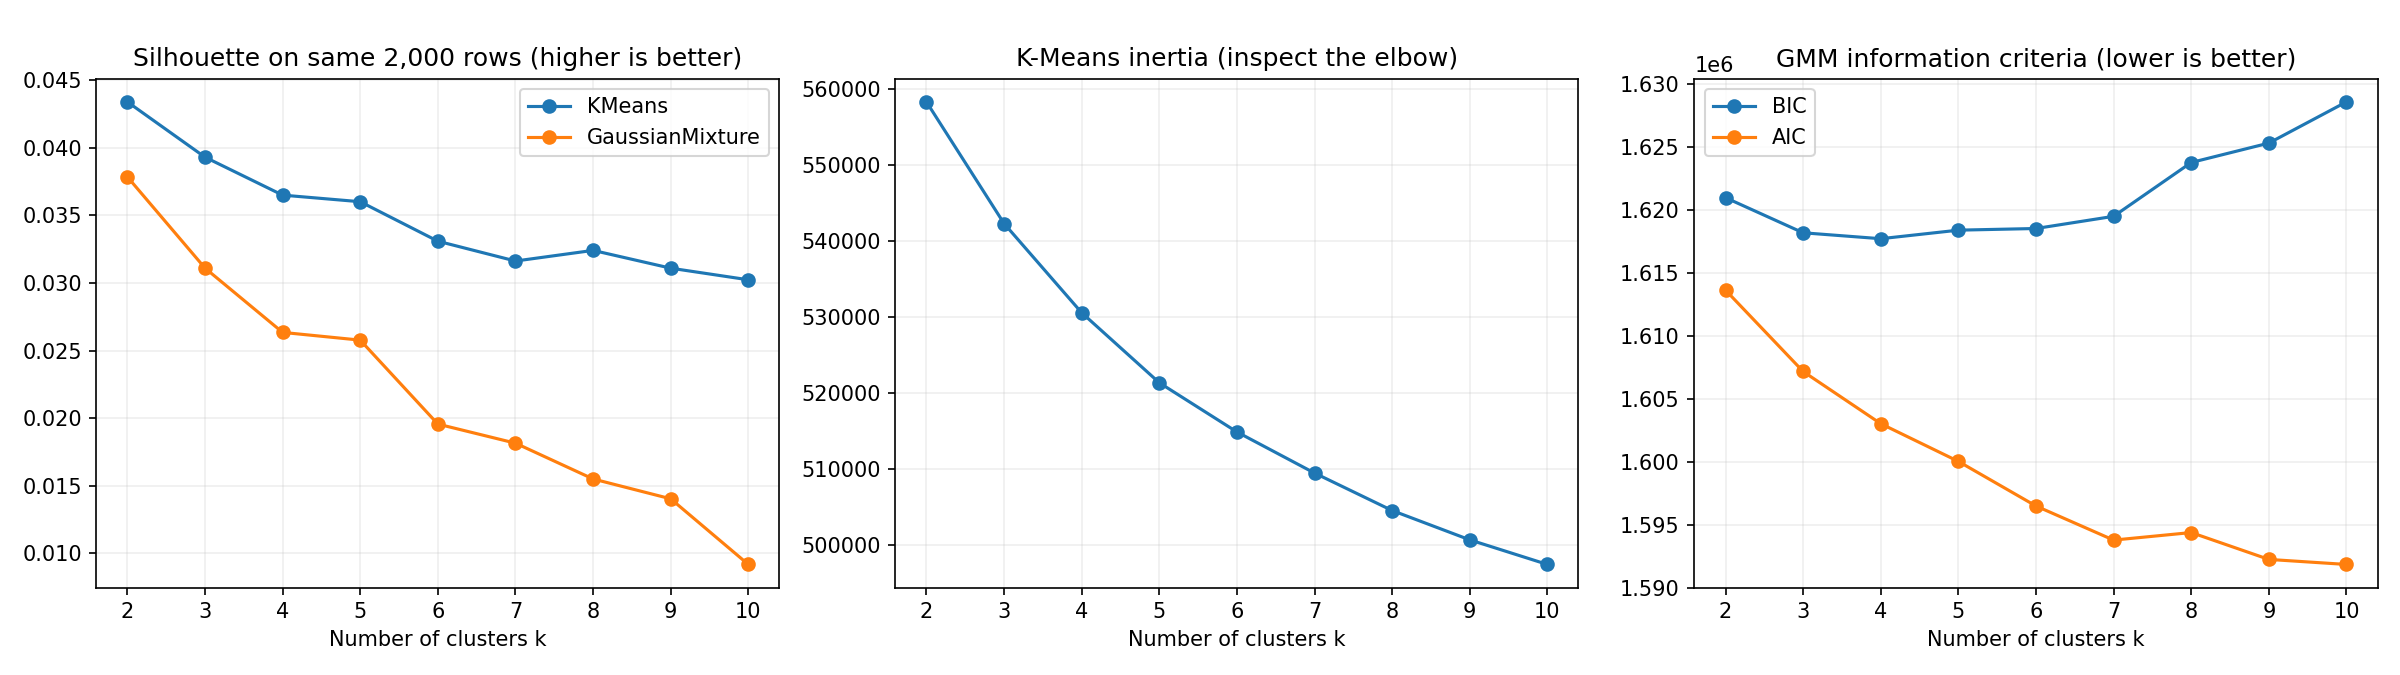

Обрані k: {'KMeans': 2, 'GaussianMixture': 4}
Увага: KMeans, k=2 на межі діапазону. Потрібно розширити пошук.


In [2]:
display(search)
display(Image(filename=str(REPORT / 'model_selection.png')))
print('Обрані k:', summary['selected_k'])
for family, k in summary['selected_k'].items():
    if k in (min(summary['k_values']), max(summary['k_values'])):
        print(f'Увага: {family}, k={k} на межі діапазону. Потрібно розширити пошук.')

## 4. Стабільність початкових умов
Порівнюємо поділи через ARI для трьох seeds. Це тест впливу ініціалізації на фіксованих даних; він не перевіряє стабільність на різних вибірках і не доводить істинність груп.

In [3]:
display(stability)
display(stability.groupby('family')['adjusted_rand_index'].agg(['min','mean','max']))
assert stability['both_converged'].all(), 'Є запуск без збіжності: перевір таблицю.' 

,family,k,seed_a,seed_b,both_converged,adjusted_rand_index
0,KMeans,2,42,43,True,0.997995
1,KMeans,2,42,44,True,0.998195
2,KMeans,2,43,44,True,0.998596
3,GaussianMixture,4,42,43,True,0.982124
4,GaussianMixture,4,42,44,True,0.987578
5,GaussianMixture,4,43,44,True,0.976593


,min,mean,max
family,,,
GaussianMixture,0.976593,0.982098,0.987578
KMeans,0.997995,0.998262,0.998596


## 5. Фінальні моделі на всіх даних
Ці значення оцінюють структуру тієї самої таблиці, на якій навчали моделі. Silhouette фінального запуску не слід напряму порівнювати з пошуковим як зміну якості: змінились fit і вибірка оцінювання.

,family,k,fit_rows,converged,fit_seconds,warnings,silhouette_sample,calinski_harabasz,davies_bouldin,observed_clusters,smallest_cluster,largest_cluster
0,KMeans,2,98000,True,0.271133,NaN,0.041044,4125.768509,4.707777,2,38397,59603
1,GaussianMixture,4,98000,True,2.794222,NaN,0.028526,2620.161911,4.802648,4,13257,36241


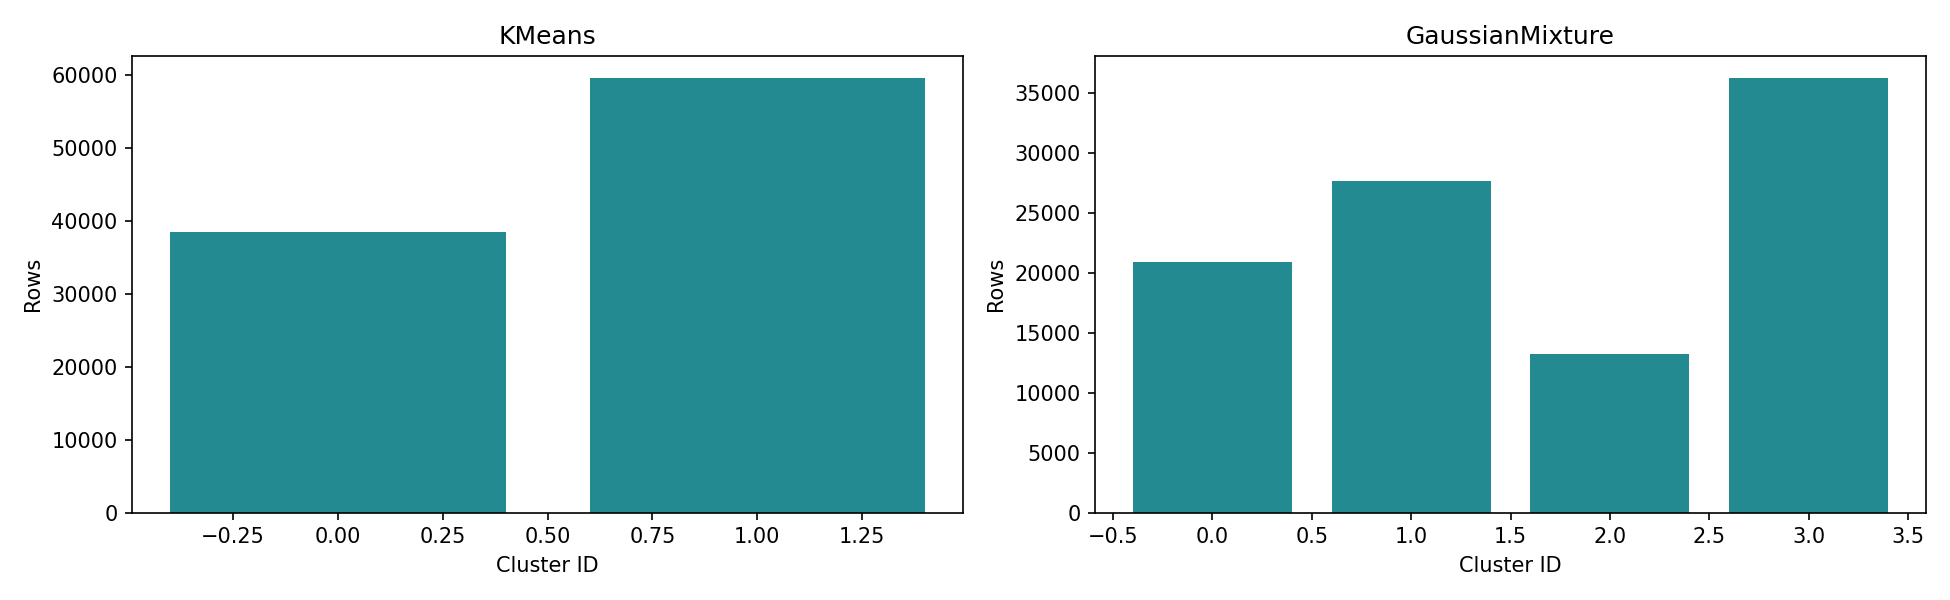

KMeans


,cluster,rows,percent
0,0,38397,39.180612
1,1,59603,60.819388


GaussianMixture


,cluster,rows,percent
0,0,20883,21.309184
1,1,27619,28.182653
2,2,13257,13.527551
3,3,36241,36.980612


Узгодженість двох фінальних моделей (ARI): 0.1933275522759571


In [4]:
display(final)
assert final['converged'].all(), 'Фінальна модель не збіглася: результати попередні.'
display(Image(filename=str(REPORT / 'cluster_sizes.png')))
for family in summary['selected_k']:
    print(family)
    display(pd.read_csv(REPORT / f'{family}_cluster_sizes.csv'))
print('Узгодженість двох фінальних моделей (ARI):', summary['model_agreement_ari'])

## 6. Візуалізація через PCA
PCA стискає 29 вимірів у дві осі, зберігаючи якомога більше загальної дисперсії. Моделі навчалися на всіх 29 ознаках, а не на цих двох осях. Показано однакові 10 000 рядків. Перекриття або відокремлення на картинці може не відображати структуру повного простору.

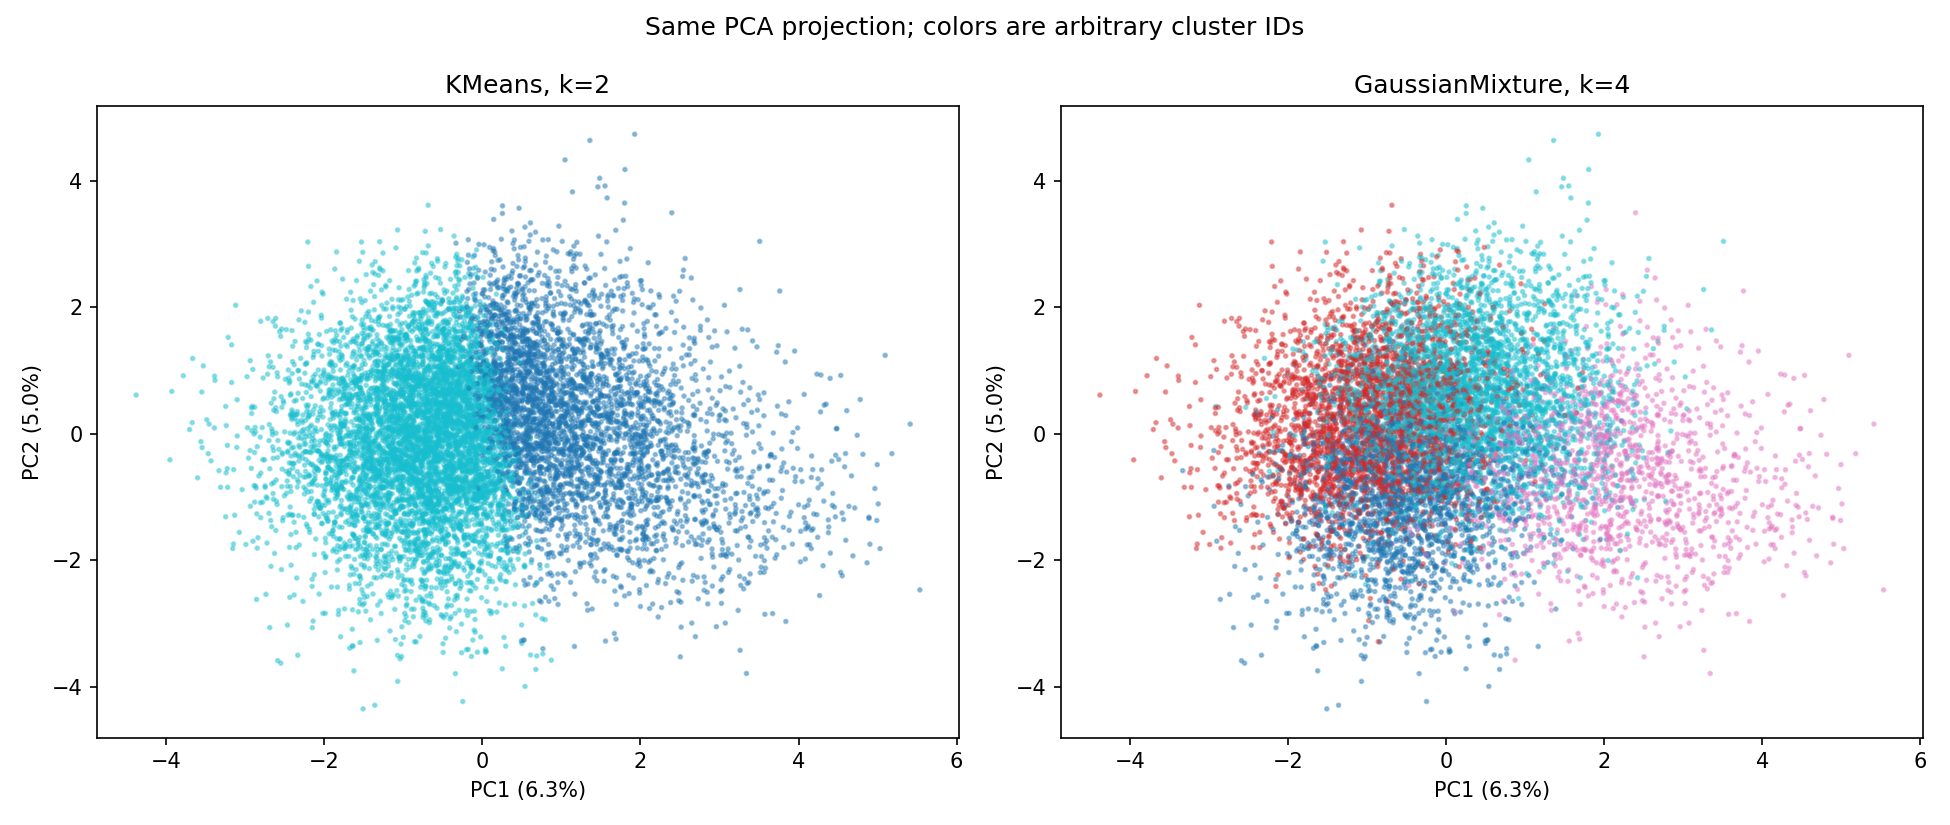

Частка дисперсії двох осей: 0.1130187080355292


In [5]:
display(Image(filename=str(REPORT / 'pca_clusters.png')))
print('Частка дисперсії двох осей:', sum(summary['pca_explained_variance_ratio']))

## 7. Чим відрізняються групи
Нижче — середні значення ознак у стандартизованих одиницях. Додатне значення означає вище загального середнього, від’ємне — нижче. Файли `*_raw_profiles.csv` містять середні у початкових одиницях. Через знеособлені ознаки не називаємо групи «несправність» або «нормальна робота» без додаткових даних.

In [6]:
for family in summary['selected_k']:
    print(family)
    display(pd.read_csv(REPORT / f'{family}_standardized_profiles.csv').round(2))

KMeans


,cluster,f_00,f_01,f_02,f_03,f_04,f_05,f_06,f_07,f_08,...,f_19,f_20,f_21,f_22,f_23,f_24,f_25,f_26,f_27,f_28
0,0,-0.01,0.02,-0.0,0.01,0.01,0.01,0.02,0.47,-0.52,...,0.0,-0.0,0.01,-0.22,-0.09,0.01,-0.07,-0.16,-0.11,0.01
1,1,0.01,-0.01,0.0,-0.01,-0.00,-0.00,-0.01,-0.30,0.34,...,-0.0,0.0,-0.01,0.14,0.06,-0.00,0.05,0.11,0.07,-0.01


GaussianMixture


,cluster,f_00,f_01,f_02,f_03,f_04,f_05,f_06,f_07,f_08,...,f_19,f_20,f_21,f_22,f_23,f_24,f_25,f_26,f_27,f_28
0,0,-0.00,-0.01,0.02,0.01,0.00,-0.01,-0.01,-0.29,0.18,...,-0.0,-0.01,0.02,0.16,0.16,-0.01,-0.07,0.15,0.34,0.07
1,1,-0.01,-0.01,-0.00,-0.00,-0.01,0.00,0.00,-0.59,0.40,...,0.0,-0.00,-0.02,0.04,0.14,-0.04,-0.07,0.03,-0.16,-0.02
2,2,0.01,0.01,0.00,0.01,-0.02,0.01,0.00,-0.39,-1.05,...,0.0,0.01,0.01,-0.42,-0.03,-0.10,-0.39,-0.37,-0.06,0.14
3,3,0.00,0.01,-0.01,-0.01,0.01,0.00,0.00,0.77,-0.02,...,-0.0,0.00,0.00,0.03,-0.19,0.07,0.24,0.02,-0.05,-0.08


## 8. Відтворення та наступні кроки
- `src/modeling.py` відтворює весь експеримент; notebook за замовчуванням читає збережений результат. Для повторного навчання: RECOMPUTE=True.
- `models/*.joblib` — локальні моделі; завантажувати тільки власні/довірені файли. На вхід подаються ті самі 29 ознак у тому самому порядку після збереженого scaler етапу 02.
- `reports/modeling/cluster_assignments.csv` зіставляє ID та кластери, але не є Kaggle submission.
- Збережено параметри вибірок, версії бібліотек, метрики, профілі та SHA-256 джерела. Перевірено завантаження моделей і незмінність сирих даних.
- Подальші кроки: розширити k при виборі на межі; порівняти covariance_type і масштабування; перевірити стабільність при повторному відборі рядків; дослідити інтерпретацію груп.
- Це початкові моделі, а не завершення семестрового завдання.

In [7]:
for note in summary['limitations']:
    print('•', note)

• Transductive baseline; no held-out performance or ground-truth accuracy claimed.
• Scaler fitted on all rows in stage 02. Search uses a fixed subset, not an independent test set.
• Integer features treated as numeric; semantics remain unconfirmed.
• Seed stability compares initializations on the same sample, not resampling stability.
• PCA is a lossy 2D illustration, not evidence of true cluster separation.
• Different selection criteria per family; no universal winning model is declared.
• A selected k lies on a search boundary: extend the range before claiming an optimum.


## Висновок першого експерименту

За Silhouette на пошуковій вибірці K-Means обрав **k=2**, а GMM за BIC — **k=4**. На повних даних Silhouette становить приблизно **0.041** і **0.029**: групи слабко відокремлені за евклідовими відстанями. Це не доводить відсутності структури, але й не дає підстав оголосити кластеризацію якісною лише за цим запуском.

Стабільність початкових умов висока: ARI приблизно **0.998** для K-Means та **0.977–0.988** для GMM. **Стабільність не дорівнює істинності** — алгоритм може стабільно знаходити спрощений поділ.

BIC та AIC GMM віддають перевагу різним k, отже вибір залежить від штрафу за складність. K-Means обрав нижню межу k=2; Silhouette не визначено для k=1, тому просто додати один кластер і порівняти цю метрику не можна. Для наступного дослідження варто додати GMM з однією компонентою як базову модель для BIC, перевірити інші коваріації та представлення ознак.

Дві осі PCA зберігають лише приблизно **11.3%** дисперсії, тому картинка не є повним представленням структури. Ми не оголошуємо жодну модель універсальним переможцем і не стверджуємо, що знайшли справжні виробничі стани.

Цей текст описує поточний збережений запуск; після зміни даних або параметрів висновки потрібно переглянути.